In [1]:
import json
import time
import getpass
from pathlib import Path

import requests
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Загружаем сохранённую базу и результаты расчётов
if not Path("vk_data.json").exists() or not Path("vk_centrality.json").exists():
    from google.colab import files
    uploaded = files.upload()

with open("vk_data.json", encoding="utf-8") as f:
    data = json.load(f)

group_ids_vk = set(data["group_ids"])
users = {user["id"]: user for user in data["profiles"]}

print("Участников группы:", len(group_ids_vk))

Участников группы: 16


In [3]:
# Уже полученные списки друзей повторно не запрашиваем
def save_data():
    with open("vk_data.tmp", "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False)
    Path("vk_data.tmp").replace("vk_data.json")


def get_friends(user_id, token):
    key = str(user_id)
    record = data["records"].get(key)

    if record and record["status"] in ("ok", "unavailable"):
        return

    friends = record["items"].copy() if record else []
    offset = record["offset"] if record else 0

    while True:
        time.sleep(1.2)
        response = requests.post(
            "https://api.vk.com/method/friends.get",
            data={
                "user_id": user_id,
                "access_token": token,
                "v": "5.199",
                "count": 5000,
                "offset": offset
            },
            timeout=30
        ).json()

        if "error" in response:
            error = response["error"]
            if error["error_code"] in (18, 30, 200):
                data["records"][key] = {
                    "items": sorted(set(friends)),
                    "offset": offset,
                    "total": record.get("total") if record else None,
                    "status": "unavailable",
                    "error_code": error["error_code"]
                }
                save_data()
                return
            raise RuntimeError(f"VK {error['error_code']}: {error['error_msg']}")

        page = response["response"]
        friends.extend(page["items"])
        offset += len(page["items"])
        complete = offset >= page["count"]

        data["records"][key] = {
            "items": sorted(set(friends)),
            "offset": offset,
            "total": page["count"],
            "status": "ok" if complete else "partial",
            "error_code": None
        }
        save_data()

        if complete:
            return
        if not page["items"]:
            raise RuntimeError("VK вернул пустую страницу. Продолжим позже.")

In [4]:
# Для продолжения сбора меняем на True
collect_data = False

if collect_data:
    token = getpass.getpass("Токен VK: ").strip()
    try:
        for user_id in sorted(group_ids_vk):
            get_friends(user_id, token)

        level_1 = set()
        for user_id in group_ids_vk:
            record = data["records"].get(str(user_id))
            if record:
                level_1.update(record["items"])
        level_1 -= group_ids_vk

        for i, user_id in enumerate(sorted(level_1), 1):
            get_friends(user_id, token)
            if i % 50 == 0:
                print(i, "/", len(level_1))

    except (RuntimeError, requests.RequestException, KeyboardInterrupt) as error:
        print("Сбор остановлен:", str(error).replace(token, "[token]"))
    finally:
        save_data()
        del token

In [5]:
friends_by_user = {}
for user_id in group_ids_vk:
    record = data["records"].get(str(user_id))
    if record:
        friends_by_user[user_id] = record["items"]

level_1 = set()
for friends in friends_by_user.values():
    level_1.update(friends)
level_1 -= group_ids_vk

friends_of_friends = {}
for user_id in level_1:
    record = data["records"].get(str(user_id))
    if record:
        friends_of_friends[user_id] = record["items"]

level_2 = set()
for friends in friends_of_friends.values():
    level_2.update(friends)
level_2 -= level_1 | group_ids_vk

pending = sum(
    str(user_id) not in data["records"]
    or data["records"][str(user_id)]["status"] == "partial"
    for user_id in level_1
)
closed = sum(
    record["status"] == "unavailable"
    for record in data["records"].values()
)

print("Участников группы:", len(group_ids_vk))
print("Друзей первого уровня:", len(level_1))
print("Новых людей второго уровня:", len(level_2))
print("Недоступных списков друзей:", closed)
print("Ещё не обработано профилей первого уровня:", pending)

Участников группы: 16
Друзей первого уровня: 1334
Новых людей второго уровня: 227708
Недоступных списков друзей: 594
Ещё не обработано профилей первого уровня: 233


In [6]:
G_vk = nx.Graph()
G_vk.add_nodes_from(sorted(group_ids_vk))

for user_id, friends in friends_by_user.items():
    for friend_id in friends:
        if user_id != friend_id:
            G_vk.add_edge(user_id, friend_id)

for user_id, friends in friends_of_friends.items():
    for friend_id in friends:
        if user_id != friend_id:
            G_vk.add_edge(user_id, friend_id)

print("Количество вершин:", G_vk.number_of_nodes())
print("Количество рёбер:", G_vk.number_of_edges())

Количество вершин: 229058
Количество рёбер: 253421


In [7]:
# Большой граф долго пересчитывается, поэтому результаты тоже сохранены
# При изменении графа нужно поставить calculate = True
calculate = False

if calculate:
    betweenness_vk = nx.betweenness_centrality(G_vk)
    closeness_vk = {
        user_id: nx.closeness_centrality(G_vk, u=user_id)
        for user_id in group_ids_vk
    }
    eigenvector_vk = nx.eigenvector_centrality(G_vk, max_iter=2000, tol=1e-10)

    saved = {
        "nodes": G_vk.number_of_nodes(),
        "edges": G_vk.number_of_edges(),
        "group_ids": sorted(group_ids_vk),
        "betweenness": {str(u): betweenness_vk[u] for u in group_ids_vk},
        "closeness": {str(u): closeness_vk[u] for u in group_ids_vk},
        "eigenvector": {str(u): eigenvector_vk[u] for u in group_ids_vk}
    }
    with open("vk_centrality.json", "w", encoding="utf-8") as f:
        json.dump(saved, f, ensure_ascii=False)
else:
    with open("vk_centrality.json", encoding="utf-8") as f:
        saved = json.load(f)

    if (saved["nodes"] != len(G_vk)
        or saved["edges"] != G_vk.number_of_edges()
        or saved["group_ids"] != sorted(group_ids_vk)):
        raise ValueError("Граф изменился. Нужно пересчитать центральности: calculate = True")

    betweenness_vk = {int(u): value for u, value in saved["betweenness"].items()}
    closeness_vk = {int(u): value for u, value in saved["closeness"].items()}
    eigenvector_vk = {int(u): value for u, value in saved["eigenvector"].items()}

In [8]:
# Выводим центральности только для участников группы
rows = []
for user_id in sorted(group_ids_vk):
    user = users[user_id]
    rows.append({
        "ID": user_id,
        "Участник": user["first_name"] + " " + user["last_name"],
        "Посредничество": betweenness_vk[user_id],
        "Близость": closeness_vk[user_id],
        "Собственный вектор": eigenvector_vk[user_id]
    })

results = pd.DataFrame(rows)
with pd.option_context("display.float_format", "{:.6g}".format):
    display(results)

for column in ["Посредничество", "Близость", "Собственный вектор"]:
    best = results.loc[results[column].idxmax()]
    print(column + ":", best["Участник"], "—", best[column])

,ID,Участник,Посредничество,Близость,Собственный вектор
0,139159408,Daniil Nisanov,0.098605,0.276188,0.00961699
1,143873880,Mikhail Chernomyrdin,3.86351e-06,0.251019,0.000326515
2,198182178,Alexander Ershov,0.000483028,0.268128,0.000394345
3,223966628,Ivan Saulin,0.0456296,0.269387,0.000129887
4,236434667,Alexander Goloktionov,0,0.239246,0.000126097
5,270876280,Gleb Boltnev,2.15548e-06,0.24348,6.70371e-05
6,288851914,Denis Davydov,0.0190531,0.229808,2.59447e-06
7,299547783,Dmitry Poluektov,0.000429464,0.251108,0.000125917
8,322111274,Gleb Nekhaev,0.0574726,0.273167,9.43674e-05
9,357111839,Andrey Kirillov,0.10697,0.290242,0.000953342


Посредничество: Ilya Medvedev — 0.11740973652937739
Близость: Ilya Medvedev — 0.2927541566496809
Собственный вектор: Daniil Nisanov — 0.009616994751797982


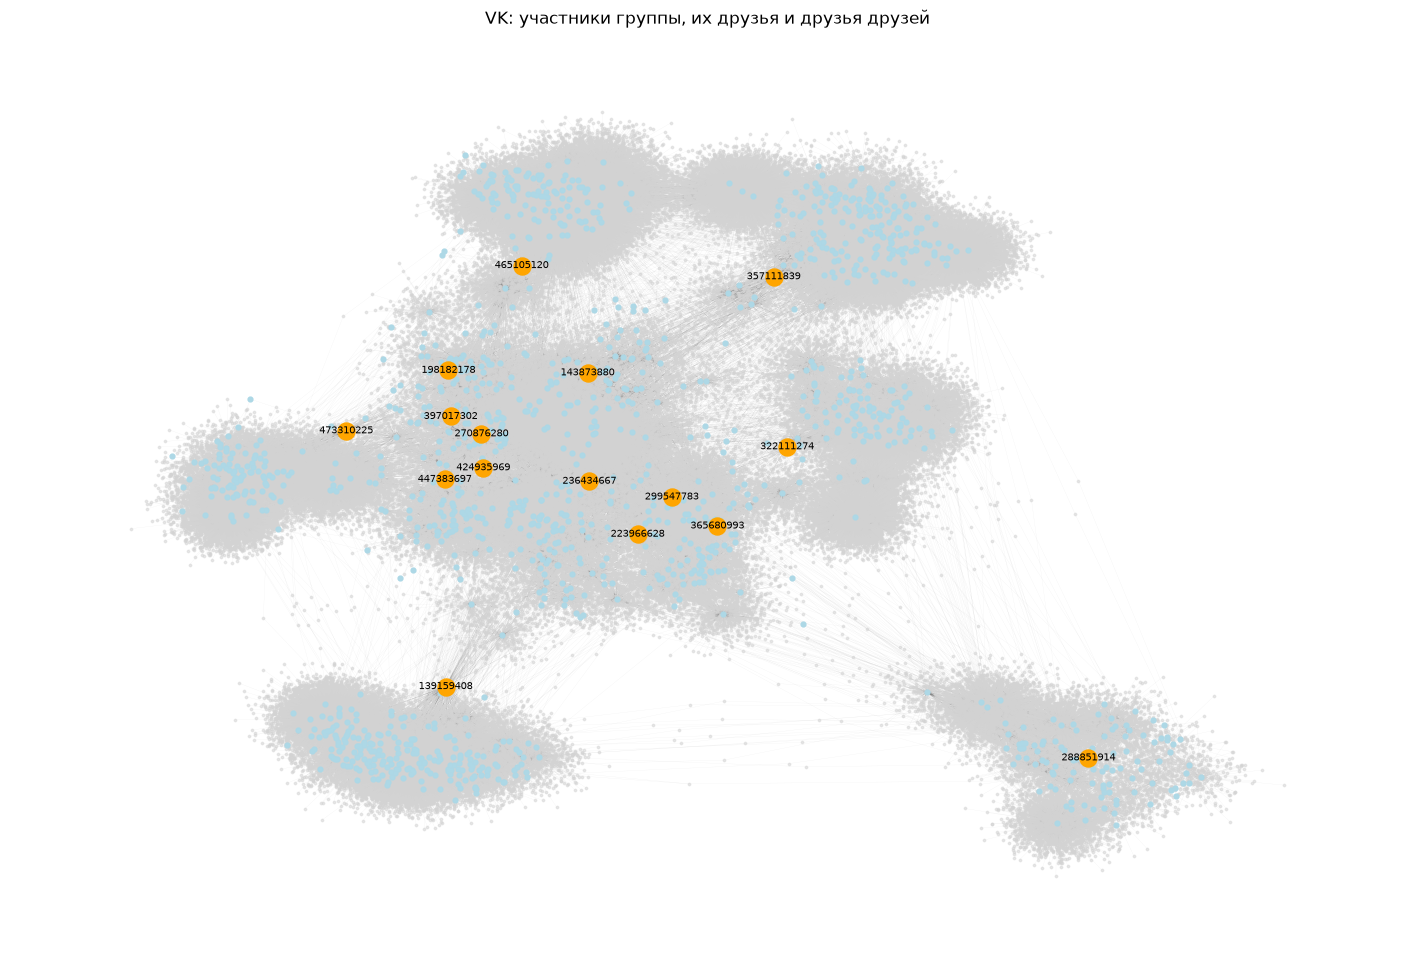

In [9]:
# Сначала размещаем группу и друзей, затем добавляем второй уровень
G_small = G_vk.subgraph(group_ids_vk | level_1)
pos_vk = nx.spring_layout(G_small, seed=42, iterations=60)
rng = np.random.default_rng(42)

for user_id in sorted(level_2):
    neighbours = [pos_vk[v] for v in G_vk[user_id] if v in G_small]
    center = np.mean(neighbours, axis=0)
    pos_vk[user_id] = center + rng.normal(0, 0.04, 2)

plt.figure(figsize=(18, 12))
nx.draw_networkx_edges(G_vk, pos_vk, width=0.2, alpha=0.06)
nx.draw_networkx_nodes(G_vk, pos_vk, nodelist=sorted(level_2),
                       node_size=3, node_color="lightgray", alpha=0.5)
nx.draw_networkx_nodes(G_vk, pos_vk, nodelist=sorted(level_1),
                       node_size=12, node_color="lightblue")
nx.draw_networkx_nodes(G_vk, pos_vk, nodelist=sorted(group_ids_vk),
                       node_size=150, node_color="orange")

labels = {u: str(u) for u in group_ids_vk}
nx.draw_networkx_labels(G_vk, pos_vk, labels=labels, font_size=7)
plt.title("VK: участники группы, их друзья и друзья друзей")
plt.axis("off")
plt.show()

Посредничество: Ilya Medvedev 465105120


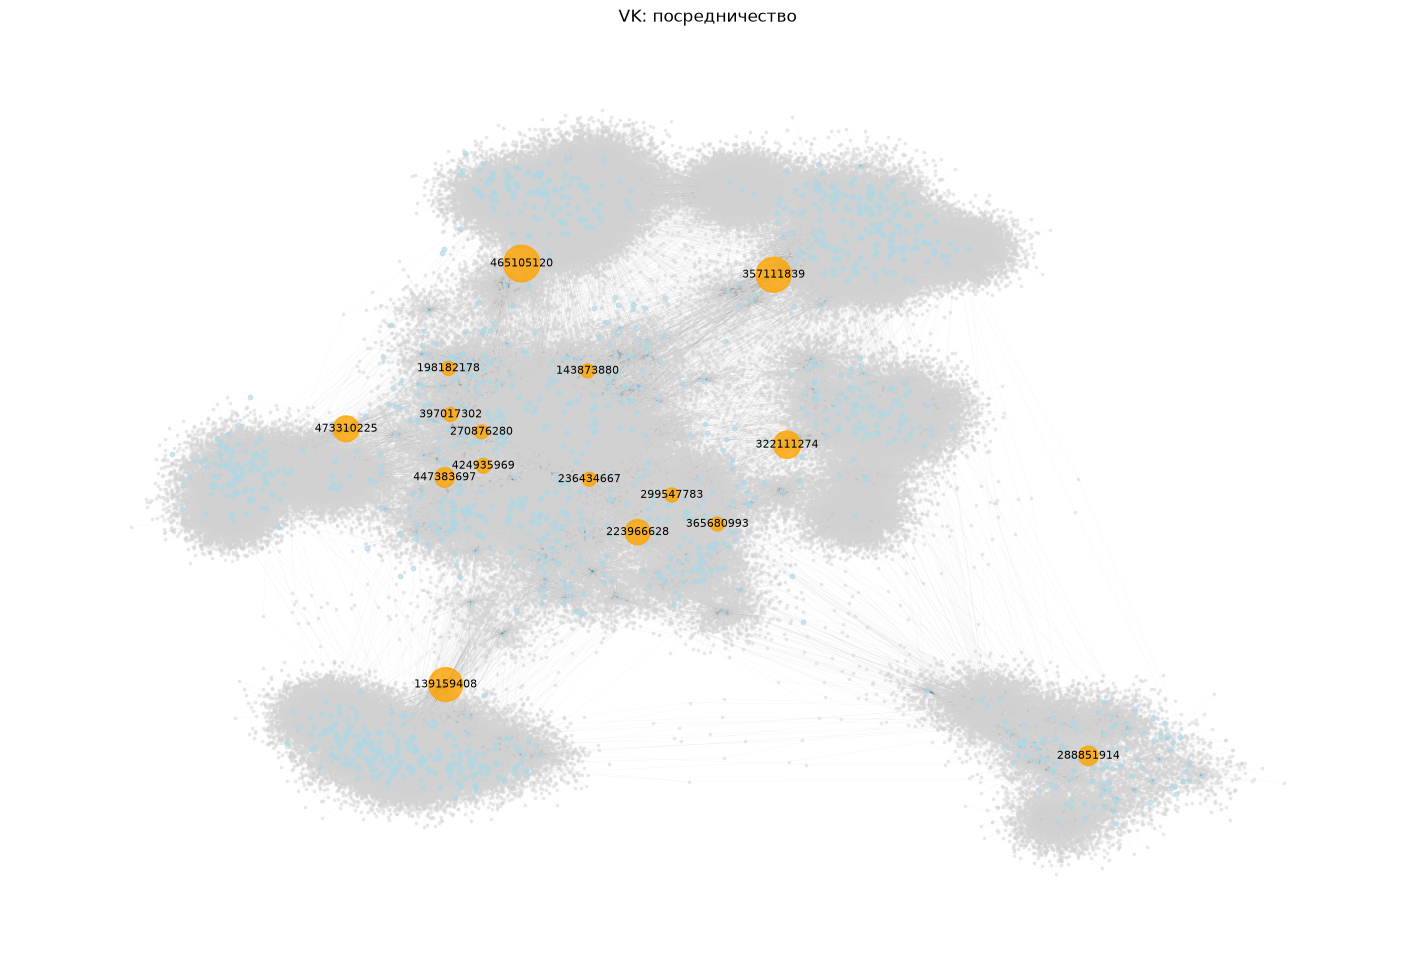

In [10]:
# Посредничество
node_sizes = [100 + betweenness_vk[u] * 5000 for u in sorted(group_ids_vk)]

plt.figure(figsize=(18, 12))
nx.draw_networkx_edges(G_vk, pos_vk, width=0.2, alpha=0.06)
nx.draw_networkx_nodes(G_vk, pos_vk, nodelist=sorted(level_2),
                       node_size=3, node_color="lightgray", alpha=0.4)
nx.draw_networkx_nodes(G_vk, pos_vk, nodelist=sorted(level_1),
                       node_size=10, node_color="lightblue", alpha=0.6)

# Меняем размер только у участников группы
nx.draw_networkx_nodes(G_vk, pos_vk, nodelist=sorted(group_ids_vk),
                       node_size=node_sizes, node_color="orange", alpha=0.8)
nx.draw_networkx_labels(G_vk, pos_vk, labels=labels, font_size=8)

best = max(sorted(group_ids_vk), key=lambda u: betweenness_vk[u])
print("Посредничество:", users[best]["first_name"], users[best]["last_name"], best)
plt.title("VK: посредничество")
plt.axis("off")
plt.show()

Близость: Ilya Medvedev 465105120


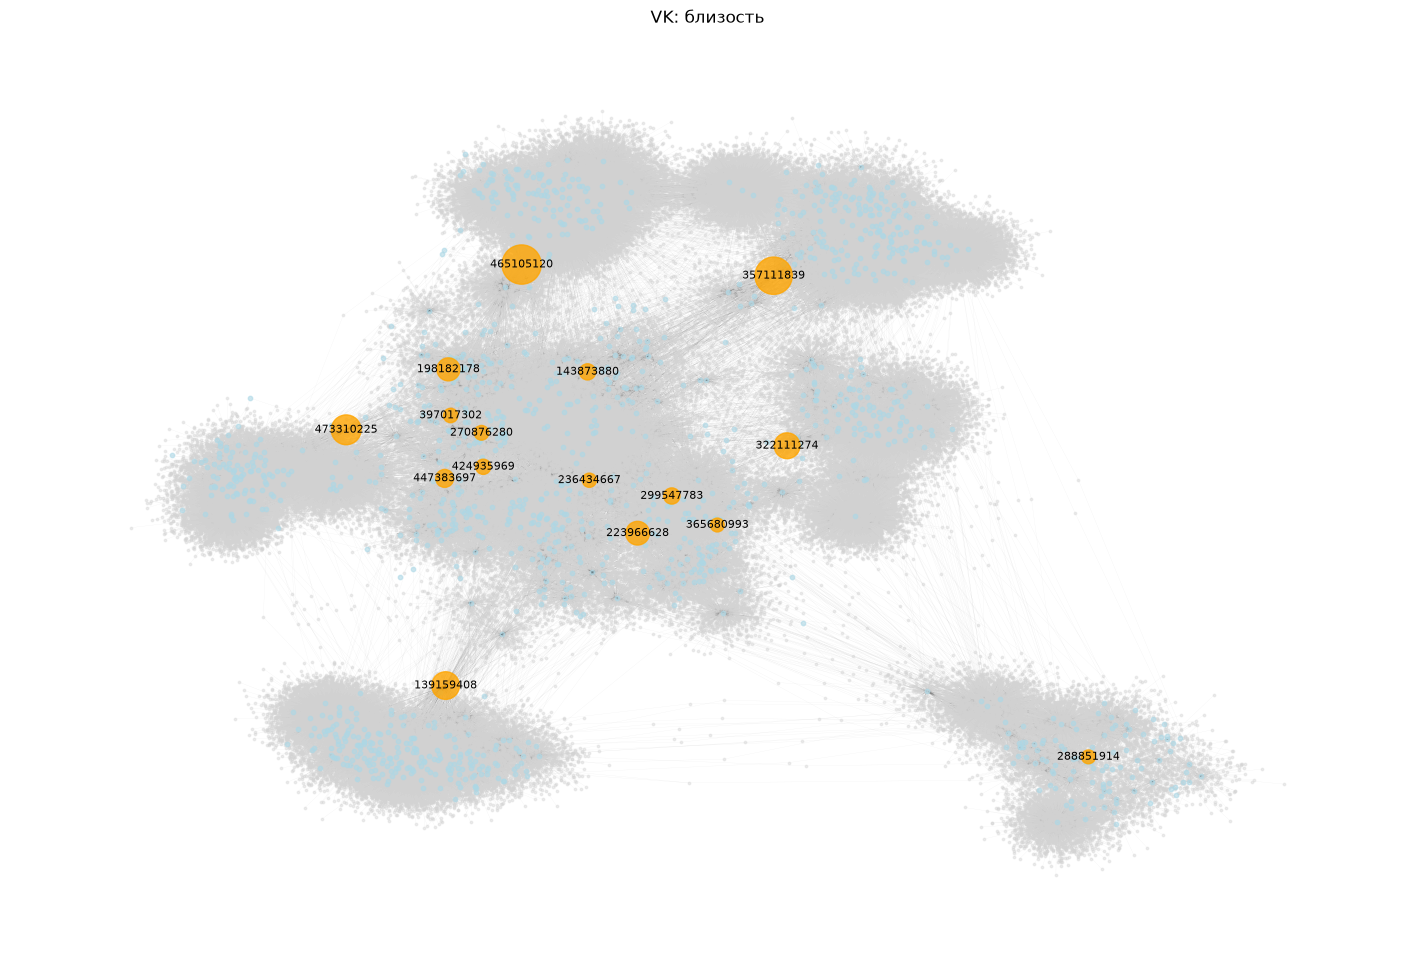

In [11]:
# Близость
minimum = min(closeness_vk.values())
maximum = max(closeness_vk.values())
node_sizes = []
for user_id in sorted(group_ids_vk):
    value = closeness_vk[user_id]
    normalized = (value - minimum) / (maximum - minimum) if maximum > minimum else 0
    node_sizes.append(100 + 700 * normalized ** 3)

plt.figure(figsize=(18, 12))
nx.draw_networkx_edges(G_vk, pos_vk, width=0.2, alpha=0.06)
nx.draw_networkx_nodes(G_vk, pos_vk, nodelist=sorted(level_2),
                       node_size=3, node_color="lightgray", alpha=0.4)
nx.draw_networkx_nodes(G_vk, pos_vk, nodelist=sorted(level_1),
                       node_size=10, node_color="lightblue", alpha=0.6)

# Меняем размер только у участников группы
nx.draw_networkx_nodes(G_vk, pos_vk, nodelist=sorted(group_ids_vk),
                       node_size=node_sizes, node_color="orange", alpha=0.8)
nx.draw_networkx_labels(G_vk, pos_vk, labels=labels, font_size=8)

best = max(sorted(group_ids_vk), key=lambda u: closeness_vk[u])
print("Близость:", users[best]["first_name"], users[best]["last_name"], best)
plt.title("VK: близость")
plt.axis("off")
plt.show()

Собственный вектор: Daniil Nisanov 139159408


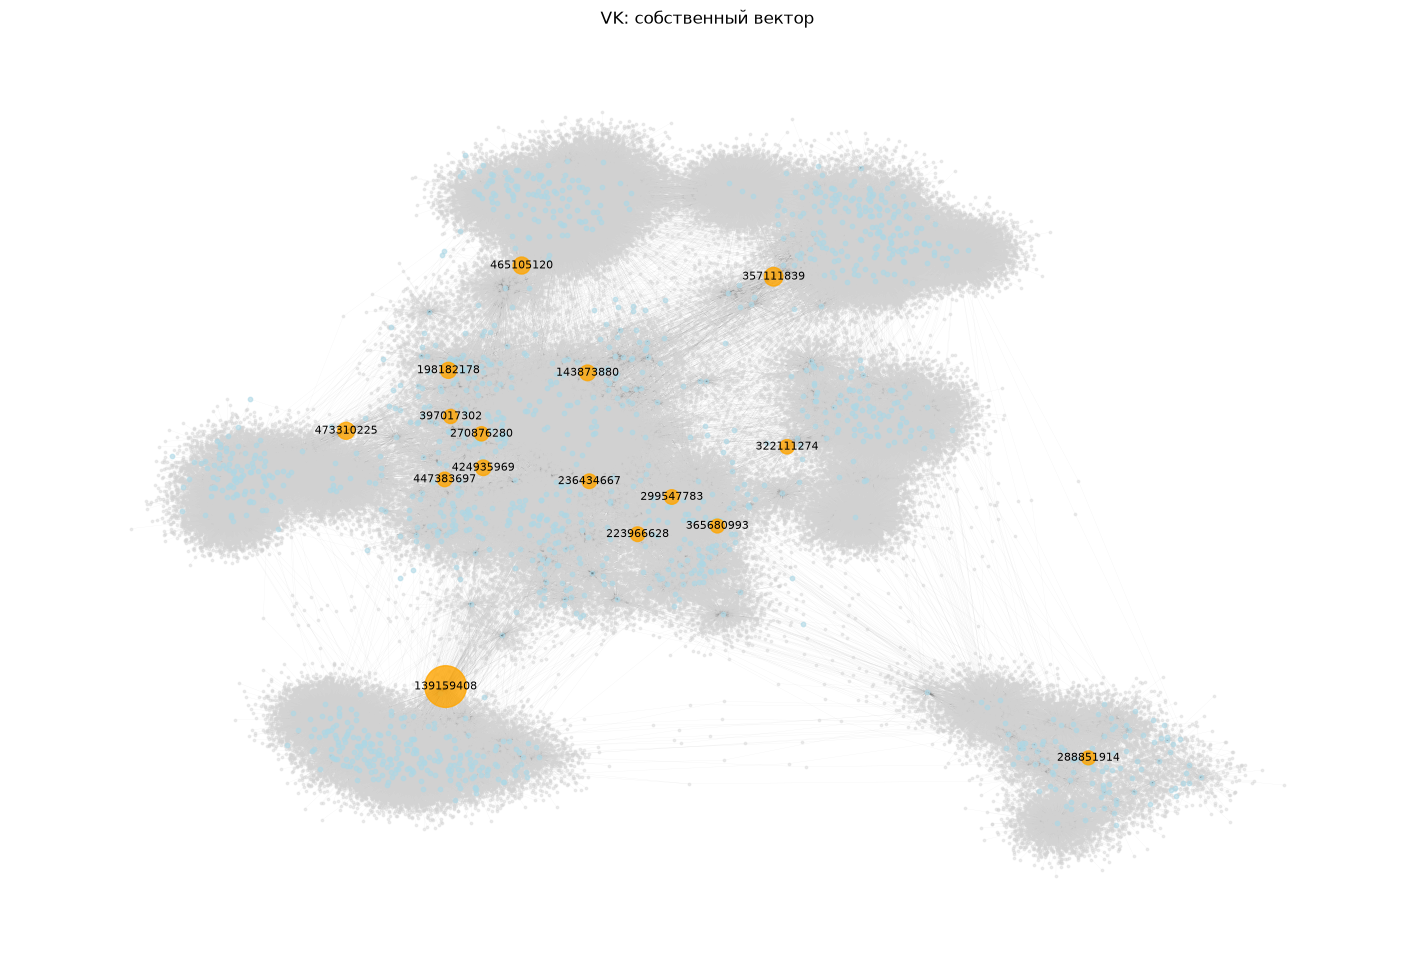

In [12]:
# Собственный вектор
maximum = max(eigenvector_vk.values())
node_sizes = [
    100 + 800 * eigenvector_vk[u] / maximum if maximum > 0 else 100
    for u in sorted(group_ids_vk)
]

plt.figure(figsize=(18, 12))
nx.draw_networkx_edges(G_vk, pos_vk, width=0.2, alpha=0.06)
nx.draw_networkx_nodes(G_vk, pos_vk, nodelist=sorted(level_2),
                       node_size=3, node_color="lightgray", alpha=0.4)
nx.draw_networkx_nodes(G_vk, pos_vk, nodelist=sorted(level_1),
                       node_size=10, node_color="lightblue", alpha=0.6)

# Меняем размер только у участников группы
nx.draw_networkx_nodes(G_vk, pos_vk, nodelist=sorted(group_ids_vk),
                       node_size=node_sizes, node_color="orange", alpha=0.8)
nx.draw_networkx_labels(G_vk, pos_vk, labels=labels, font_size=8)

best = max(sorted(group_ids_vk), key=lambda u: eigenvector_vk[u])
print("Собственный вектор:", users[best]["first_name"], users[best]["last_name"], best)
plt.title("VK: собственный вектор")
plt.axis("off")
plt.show()

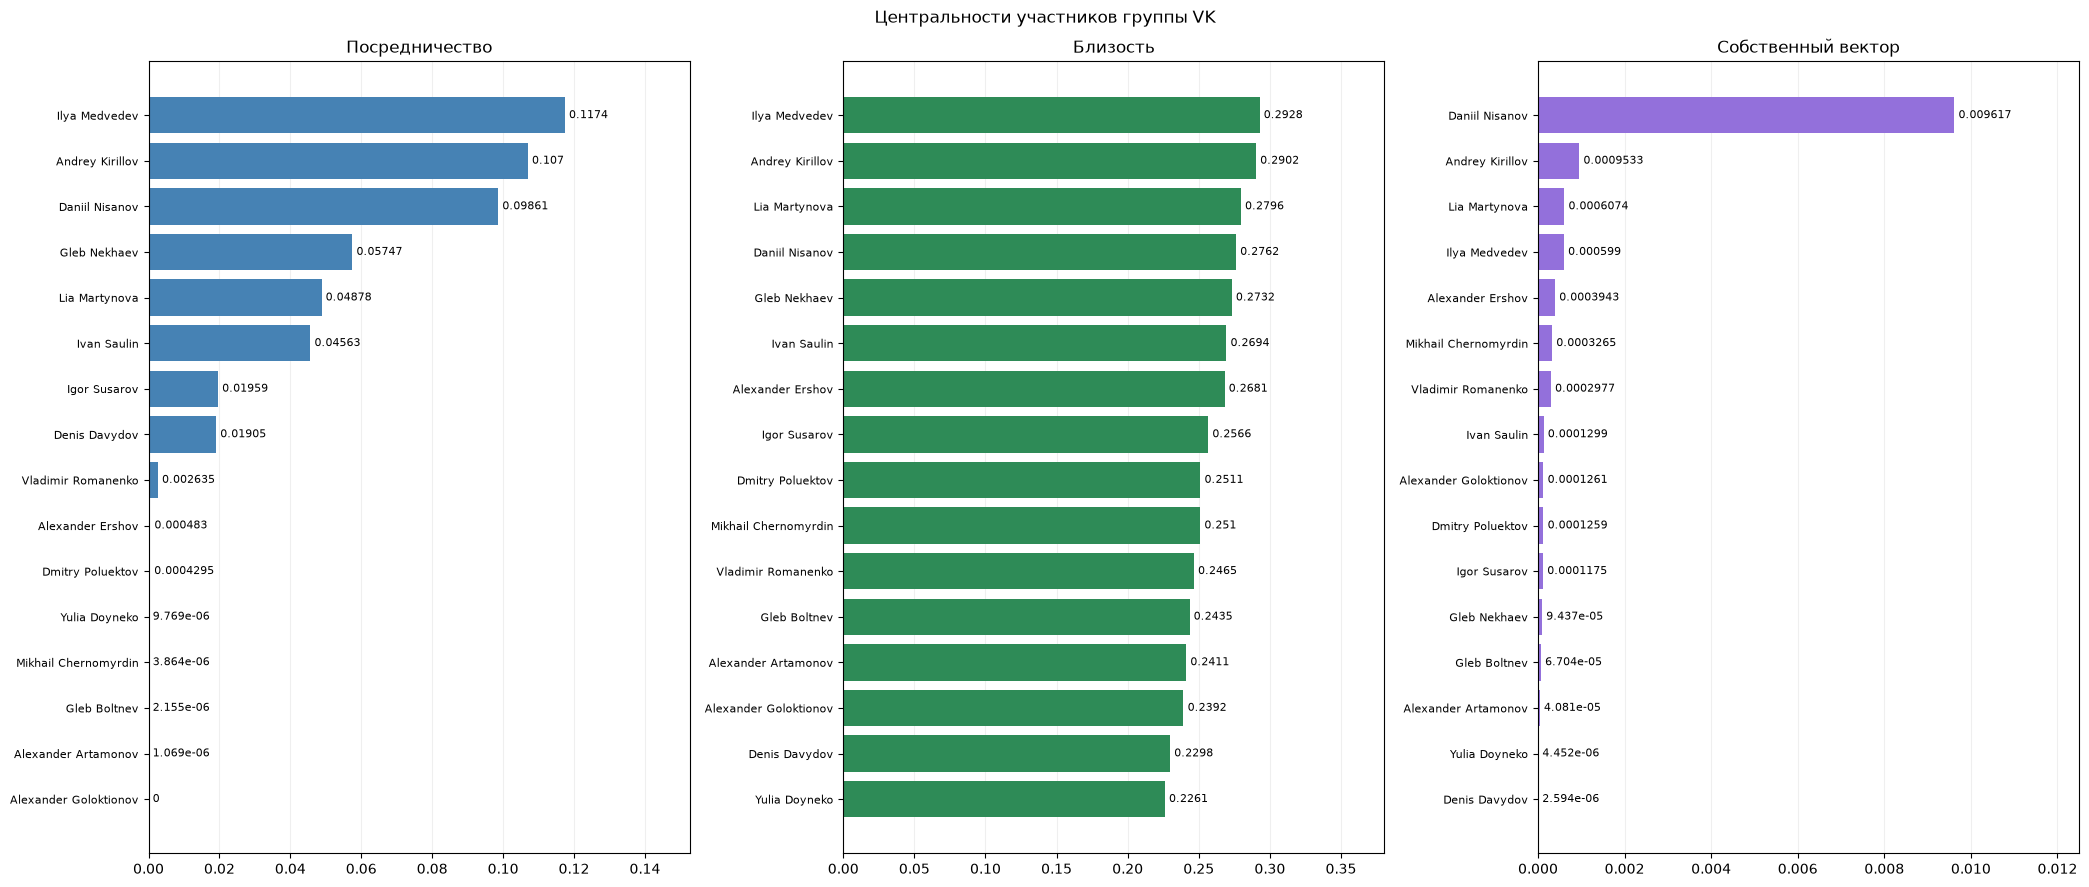

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(21, 9))
columns = ["Посредничество", "Близость", "Собственный вектор"]
colors = ["steelblue", "seagreen", "mediumpurple"]

for ax, column, color in zip(axes, columns, colors):
    table = results.sort_values(column)
    bars = ax.barh(table["Участник"], table[column], color=color)
    ax.bar_label(bars, labels=[f"{value:.4g}" for value in table[column]],
                 padding=3, fontsize=8)
    ax.set_xlim(0, max(table[column]) * 1.3 or 1)
    ax.set_title(column)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", labelsize=8)

plt.suptitle("Центральности участников группы VK")
plt.tight_layout()
plt.show()

In [14]:
# Facebook
if not Path("fb.zip").exists():
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))
else:
    filename = "fb.zip"

In [15]:
import zipfile

with zipfile.ZipFile(filename, "r") as zip_ref:
    zip_ref.extractall("facebook_data")

In [16]:
import os

for root, dirs, files in os.walk("facebook_data"):
    print("ПАПКА:", root)

    for file in files[:10]:
        print("   ", file)

ПАПКА: facebook_data
ПАПКА: facebook_data/facebook
    3980.feat
    3980.featnames
    1912.egofeat
    686.edges
    686.featnames
    348.edges
    414.circles
    3437.egofeat
    414.feat
    1684.featnames


In [17]:
file_path = "facebook_data/facebook/0.edges"

2519
333



Самый центральный из группы по посредничеству: 322


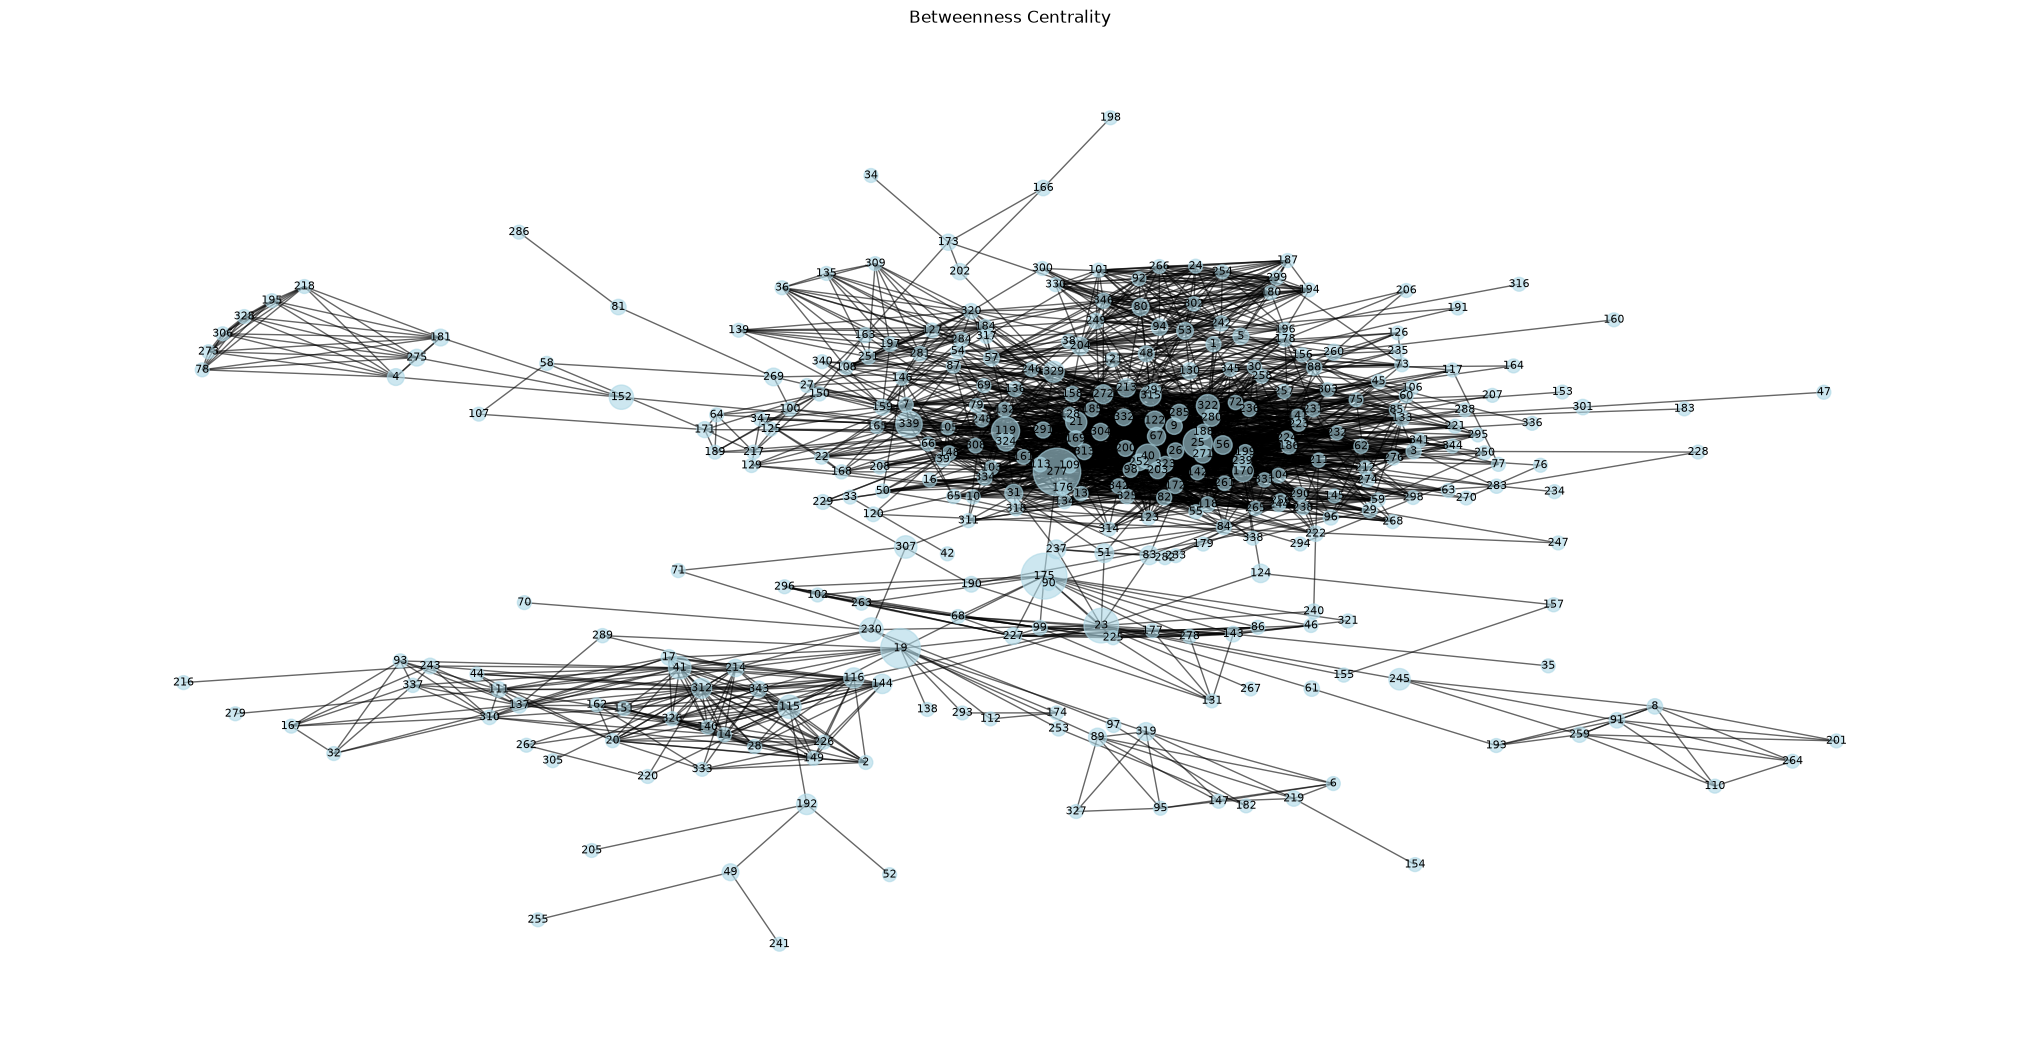


Самый центральный из группы по близости: 322


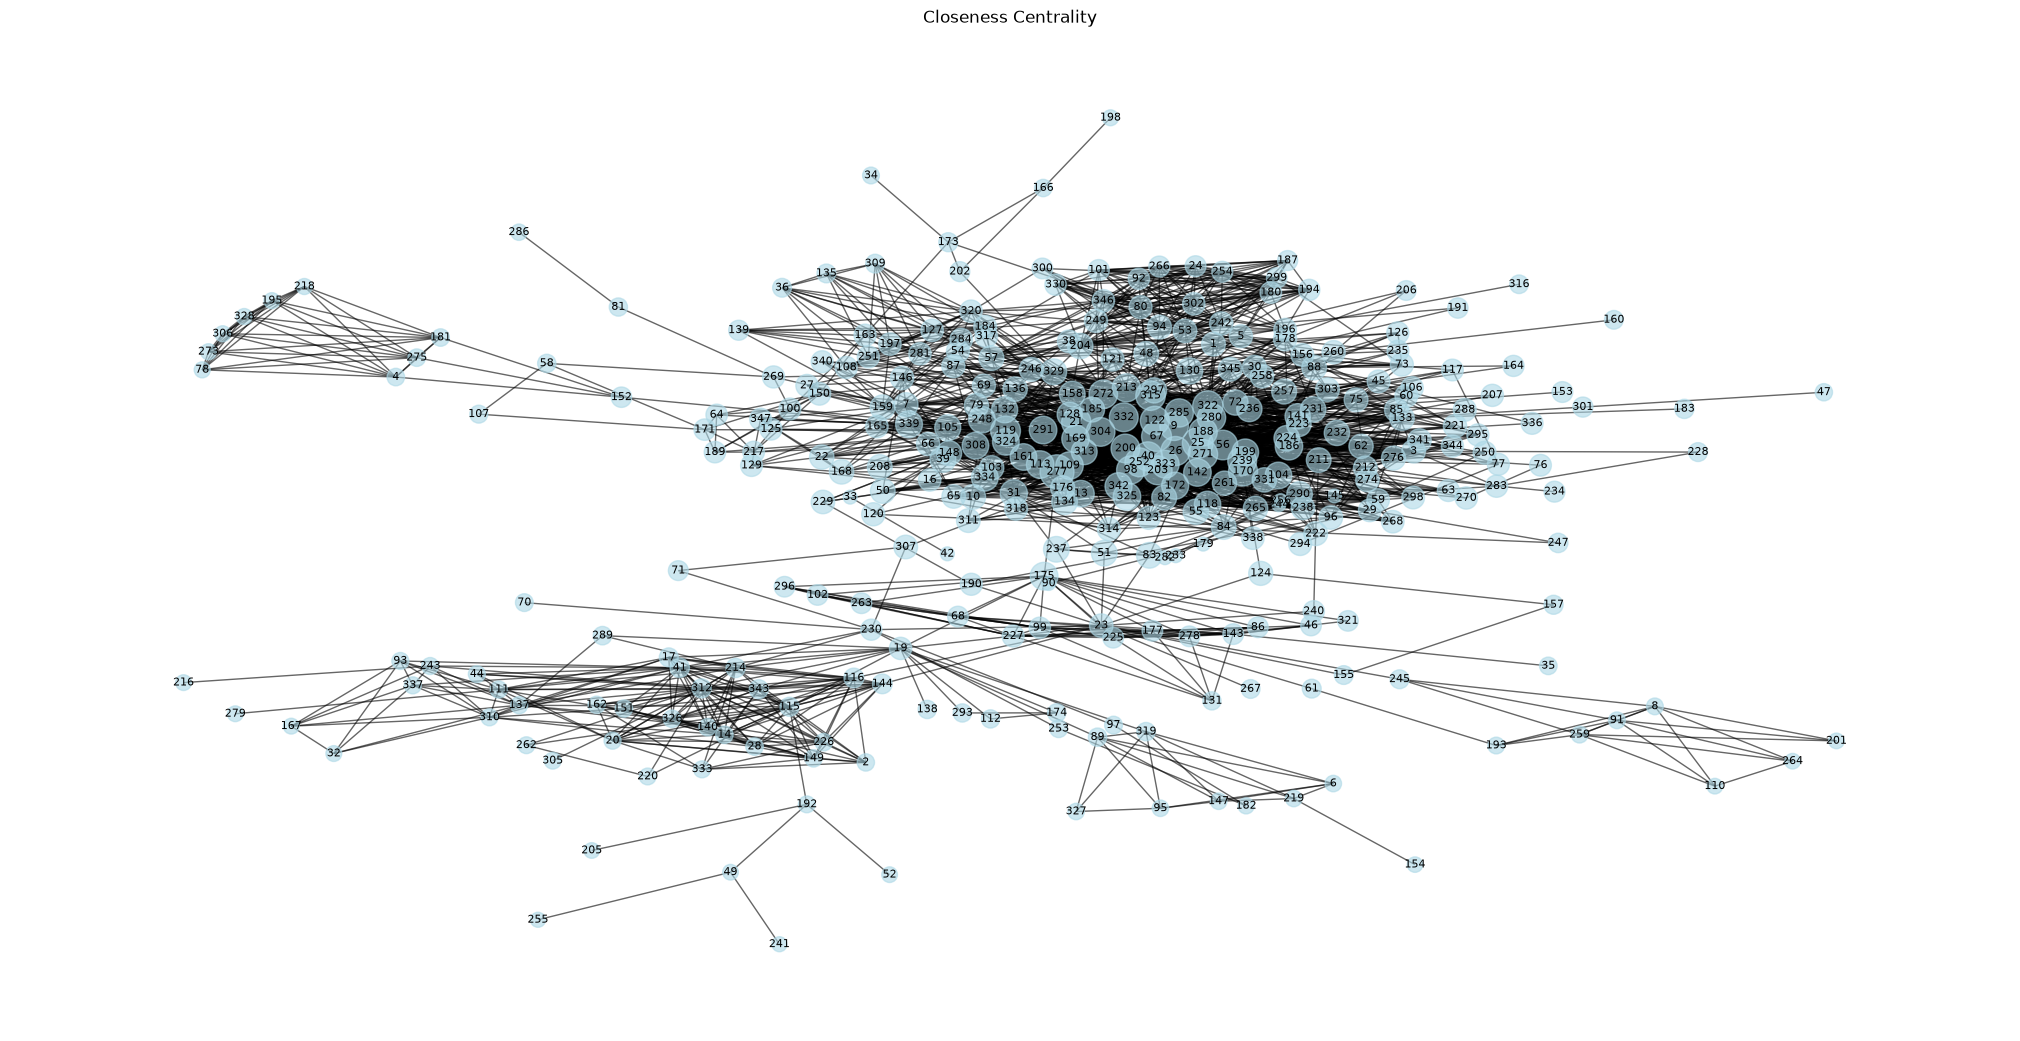


Самый центральный из группы по собственному вектору: 271


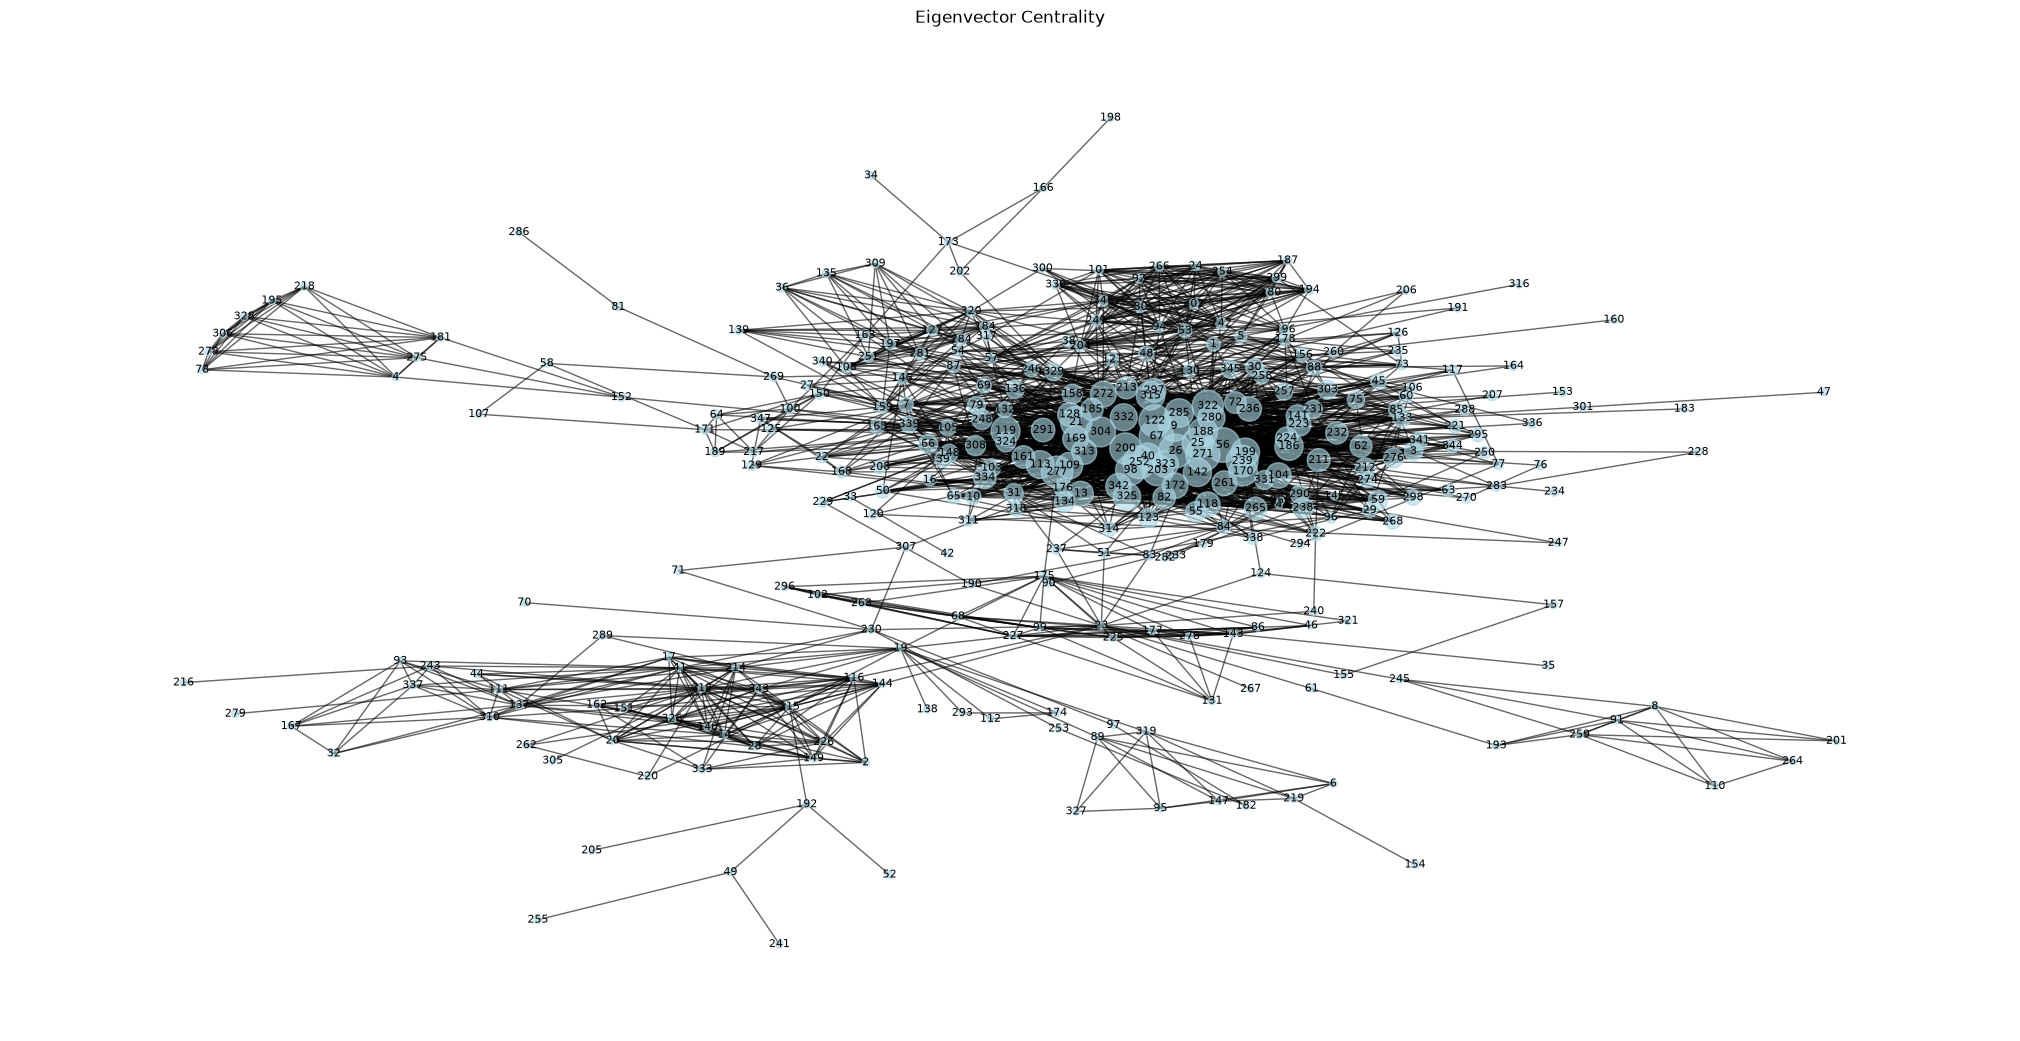


Результаты для членов группы:
236 Betweenness = 0.0036 Closeness = 0.3213 Eigenvector = 0.0923
186 Betweenness = 0.0055 Closeness = 0.3457 Eigenvector = 0.1286
122 Betweenness = 0.0228 Closeness = 0.3629 Eigenvector = 0.165
285 Betweenness = 0.0137 Closeness = 0.3551 Eigenvector = 0.1302
24 Betweenness = 0.0001 Closeness = 0.2614 Eigenvector = 0.0034
346 Betweenness = 0.0047 Closeness = 0.2841 Eigenvector = 0.0091
271 Betweenness = 0.015 Closeness = 0.3684 Eigenvector = 0.1937
304 Betweenness = 0.0135 Closeness = 0.3595 Eigenvector = 0.145
176 Betweenness = 0.0002 Closeness = 0.3072 Eigenvector = 0.0438
9 Betweenness = 0.0099 Closeness = 0.3583 Eigenvector = 0.1487
130 Betweenness = 0.01 Closeness = 0.3318 Eigenvector = 0.0223
329 Betweenness = 0.0319 Closeness = 0.3277 Eigenvector = 0.0447
204 Betweenness = 0.0163 Closeness = 0.3216 Eigenvector = 0.0124
213 Betweenness = 0.0179 Closeness = 0.3527 Eigenvector = 0.0751
252 Betweenness = 0.0107 Closeness = 0.3612 Eigenvector = 0.1772
33

In [18]:
import networkx as nx

G = nx.Graph()

with open(file_path, "r") as f:
  for line in f:
    a, b = map(int, line.split())

    G.add_edge(a, b)

print(G.number_of_edges())
print(G.number_of_nodes())



import matplotlib.pyplot as plt




group_ids = list(G.nodes())[:30]





betweenness = nx.betweenness_centrality(G)

node_sizes_betweenness = []

for node in G.nodes():
  node_sizes_betweenness.append(betweenness[node] * 4000 + 100)

plt.figure(figsize=(20, 10))

pos = nx.kamada_kawai_layout(G)

nx.draw(
    G,
    pos,
    with_labels=False,
    node_size=node_sizes_betweenness,
    alpha=0.6,
    node_color="lightblue"
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=8
)

best_betweenness_group = max(
    group_ids,
    key=lambda node: betweenness[node]
)
print("\nСамый центральный из группы по посредничеству:", best_betweenness_group)

plt.title("Betweenness Centrality")
plt.show()





closeness = nx.closeness_centrality(G)

closeness_min = min(closeness.values())
closeness_max = max(closeness.values())

closeness_normalized = {}

for node in G.nodes():
    closeness_normalized[node] = (
        (closeness[node] - closeness_min)
        / (closeness_max - closeness_min)
    )

node_sizes_closeness = []

for node in G.nodes():
  value = closeness_normalized[node]
  size = 100 + 500 * (value ** 3)
  node_sizes_closeness.append(size)


plt.figure(figsize=(20, 10))

nx.draw(
    G,
    pos,
    with_labels=False,
    node_size=node_sizes_closeness,
    alpha=0.6,
    node_color="lightblue"
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=8
)

best_closeness_group = max(
    group_ids,
    key=lambda node: closeness[node]
)
print("\nСамый центральный из группы по близости:",best_closeness_group)

plt.title("Closeness Centrality")
plt.show()






eigenvector = nx.eigenvector_centrality(
    G,
    max_iter=1000
)

node_sizes_eigenvector = []

for node in G.nodes():
    node_sizes_eigenvector.append(
        eigenvector[node] * 3000 + 30
    )

plt.figure(figsize=(20, 10))

pos = nx.kamada_kawai_layout(G)

nx.draw(
    G,
    pos,
    with_labels=False,
    node_size=node_sizes_eigenvector,
    alpha=0.6,
    node_color="lightblue"
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=8
)

best_eigenvector_group = max(
    group_ids,
    key=lambda node: eigenvector[node]
)
print("\nСамый центральный из группы по собственному вектору:",best_eigenvector_group)

plt.title("Eigenvector Centrality")
plt.show()



print("\nРезультаты для членов группы:")
for node in group_ids:
  print(
      node,
      'Betweenness =', round(betweenness[node], 4),
      'Closeness =', round(closeness[node], 4),
      'Eigenvector =', round(eigenvector[node], 4),

  )


